In [9]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing

In [10]:
# Load the file using the path exactly as it was saved
# file_path = '../data/embeddings_2026-1-10_15-24-10_2176_32768_blocks.28.mlp.l3_16384_0.pt'
# Genome formed only by not codings regions
# file_path = '../data/embeddings_2026-1-27_12-28-7_2176_32768_blocks.28.mlp.l3_16384_0_0.pt'
file_path = '../data/embeddings/embeddings_2026-1-28_19-22-47_2176_32768_blocks.28.mlp.l3_16384_0_0.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors
starts_list = data['starts']
ends_list = data['ends']

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

# Sanity checks
assert len(ids) == loaded_embeds.shape[0] == len(starts_list) == len(ends_list)

print("IDs array shape:", loaded_ids.shape)
print("Embeddings array shape:", loaded_embeds.shape) 

df = pd.DataFrame(
    data=loaded_embeds[:,:],
    index=loaded_ids[:],
    columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]
) 


# Take a look
df.head()

IDs array shape: (5861,)
Embeddings array shape: (5861, 4096)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,46.250,-87.00,-73.00,95.0,93.500,-43.000,-116.5,42.25,-84.0,-250.0,...,-40.000,31.250,-61.00,-55.50,-61.25,69.5000,73.0,-111.5,-77.50,-7.18750
NC_025467,55.500,-96.50,-81.00,96.5,108.500,-46.250,-115.5,44.50,-67.5,-270.0,...,-49.750,35.750,-57.75,-58.25,-58.50,101.0000,82.5,-120.5,-33.75,-20.37500
AJ298298,25.625,-58.75,-44.25,128.0,-2.625,-16.625,-121.5,14.25,-78.5,-120.0,...,-19.375,9.125,-38.50,-36.75,-22.00,8.6875,27.0,-104.0,-48.50,-5.96875
NC_025436,62.500,-81.00,-78.50,96.0,63.750,-31.125,-109.0,38.75,-85.0,-223.0,...,-42.500,26.250,-62.25,-50.50,-52.25,84.5000,79.5,-117.5,-14.00,-22.75000
NC_025436,54.500,-81.00,-82.00,89.5,61.500,-31.875,-106.0,38.25,-85.0,-217.0,...,-37.000,22.875,-62.75,-47.25,-57.75,75.0000,67.5,-113.5,-49.50,-14.75000


In [11]:
# Path to the Excel file containing lifecycle information
excel_file_path = "../data/journal.pcbi.1012525.s001.xlsx"
# Training
sheet_names = pd.ExcelFile(excel_file_path).sheet_names
# Training dataset
training = pd.read_excel(excel_file_path, sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel(excel_file_path, sheet_name=sheet_names[1])

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

# Standardize lifecycle labels and populate the map
for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

Aligned labels length: 5861


In [12]:
# Set global random state for following models
RANDOM_STATE = 0

train_ids = set(training['Accession number'].astype(str).str.strip())
test_ids = set(test['Accession number'].astype(str).str.strip())

# Prepare feature and labels
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)


X_train = df.iloc[train_indices]
X_test = df.iloc[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

# Normalize data (row-wise)
normalizer = preprocessing.Normalizer()
X_train = normalizer.transform(X_train)
X_test = normalizer.transform(X_test)

print(f"Data Split Loaded: {len(X_train)} Train, {len(X_test)} Test")


Data Split Loaded: 5048 Train, 813 Test


In [14]:
from joblib import load
from utils import compute_and_print_metrics

# We import svaed model tuned on normalized data and summed embeddings
# With these, we only use it in inference mode
model = load("hgb_model.joblib")
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

y_pred = np.concat([y_train_pred, y_test_pred])
y_true = np.concat([y_train, y_test])
# Statistics on the entire dataset
compute_and_print_metrics("HGB Model", y_true, y_pred, pos_label="lysogenic")
# Statistics on test set only
compute_and_print_metrics("HGB Model - Test", y_test, y_test_pred, pos_label="lysogenic")


HGB Model RESULTS
------------------------------
Sensitivity (Recall): 0.7942
Specificity:          0.9719
Accuracy:             0.9302
F1-Score:             0.8423
MCC:                  0.8001
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic      4360             126
Actual lysogenic   283            1092

HGB Model - Test RESULTS
------------------------------
Sensitivity (Recall): 0.7769
Specificity:          0.9772
Accuracy:             0.9176
F1-Score:             0.8488
MCC:                  0.7992
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       558              13
Actual lysogenic    54             188


In [27]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_norm = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=0,
    scoring='loss',
    l2_regularization=0.1,
    learning_rate=0.2,
    max_depth=5,
    max_iter=1000
)

hgb_norm.fit(X_train, y_train)
y_pred_test_hgb_norm = hgb_norm.predict(X_test)
compute_and_print_metrics("HGB Model - Test", y_test, y_pred_test_hgb_norm, pos_label="lysogenic")


HGB Model - Test RESULTS
------------------------------
Sensitivity (Recall): 0.8017
Specificity:          0.9860
Accuracy:             0.9311
F1-Score:             0.8739
MCC:                  0.8334
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       563               8
Actual lysogenic    48             194


In [28]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, f1_score, accuracy_score, precision_score, recall_score, matthews_corrcoef
# Tune decision threshold on the optimized model
f1_scorer = make_scorer(f1_score, pos_label="lysogenic")
mcc_scorer = make_scorer(matthews_corrcoef)
print("Tuning Decision Threshold...")
hgb_final_f1 = TunedThresholdClassifierCV(hgb_norm, scoring=f1_scorer, cv=5)
hgb_final_f1.fit(X_train, y_train)

hgb_final_mcc = TunedThresholdClassifierCV(hgb_norm, scoring=mcc_scorer, cv=5)
hgb_final_mcc.fit(X_train, y_train)


print(f"HGB Optimal Threshold (F1 Score): {hgb_final_f1.best_threshold_:.3f}")

# HistGradientBoosting in sklearn handles string labels natively!
y_pred_hgb_f1 = hgb_final_f1.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (F1 Score)", y_test, y_pred_hgb_f1)

print(f"HGB Optimal Threshold (MCC): {hgb_final_mcc.best_threshold_:.3f}")

# HistGradientBoosting in sklearn handles string labels natively!
y_pred_hgb_mcc = hgb_final_mcc.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (MCC)", y_test, y_pred_hgb_mcc)

Tuning Decision Threshold...
HGB Optimal Threshold (F1 Score): 0.313

HistGradientBoosting (F1 Score) RESULTS
------------------------------
Sensitivity (Recall): 0.8182
Specificity:          0.9807
Accuracy:             0.9323
F1-Score:             0.8780
MCC:                  0.8359
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       560              11
Actual lysogenic    44             198
HGB Optimal Threshold (MCC): 0.687

HistGradientBoosting (MCC) RESULTS
------------------------------
Sensitivity (Recall): 0.8182
Specificity:          0.9807
Accuracy:             0.9323
F1-Score:             0.8780
MCC:                  0.8359
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       560              11
Actual lysogenic    44             198


In [17]:
# We want the probability that each sample is lysogenic
pos_class = 'lysogenic'
pos_index = np.where(model.classes_ == pos_class)[0][0]

train_probs = model.predict_proba(X_train)[:, pos_index]
test_probs  = model.predict_proba(X_test)[:, pos_index]

train_preds = model.predict(X_train)
test_preds  = model.predict(X_test)

train_accessions = df.index[train_indices]
test_accessions  = df.index[test_indices]

In [18]:
from sklearn.cluster import HDBSCAN # Requires scikit-learn >= 1.3
from sklearn.decomposition import PCA

X_combined = np.vstack([X_train, X_test])
probs_combined = np.concatenate([train_probs, test_probs])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_combined)
clusterer = HDBSCAN(min_cluster_size=15)
cluster_labels = clusterer.fit_predict(X_pca)

/Users/francescostella/anaconda3/envs/thesis/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


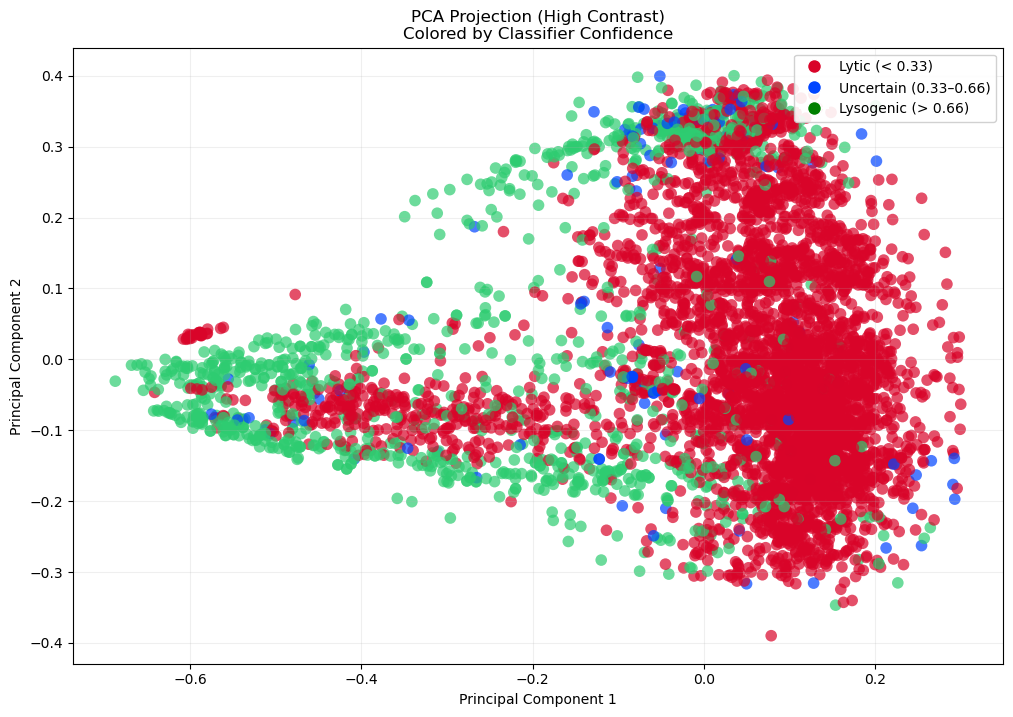

Running t-SNE... this may take a moment.


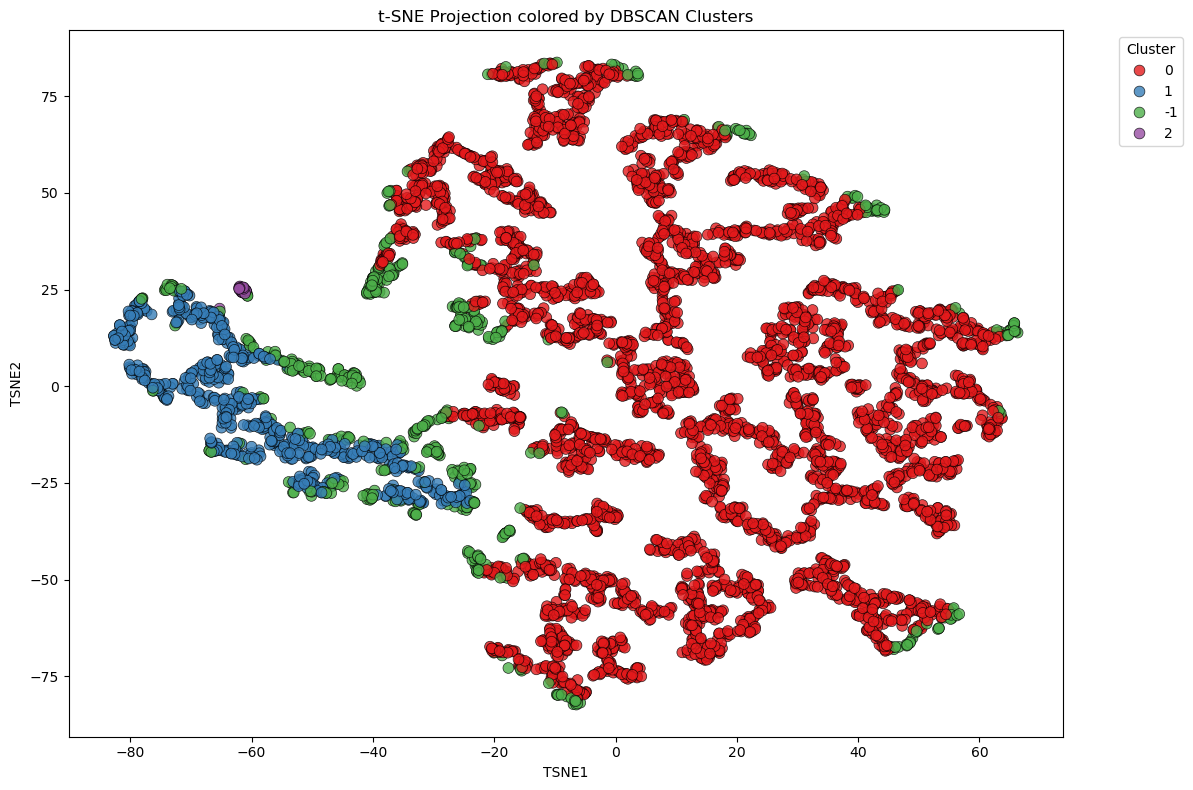

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
import pandas as pd
import numpy as np
from matplotlib.lines import Line2D

# Define high-contrast, vivid colors
# Lytic (< 0.33): Crimson Red
# Uncertain (0.33-0.66): Bright Blue
# Lysogenic (> 0.66): Deep Green
vivid_colors = []
for prob in probs_combined:
    if prob < 0.33:
        vivid_colors.append('#D90429')  # Vivid Red
    elif 0.33 <= prob <= 0.66:
        vivid_colors.append('#0044FF')  # Bright Blue
    else:
        vivid_colors.append('#2ecc71')

plt.figure(figsize=(12, 8))

# Scatter plot
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=vivid_colors, alpha=0.7, s=70, edgecolor='none')

# Custom Legend with strong colors
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#D90429', markersize=10, label='Lytic (< 0.33)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#0044FF', markersize=10, label='Uncertain (0.33–0.66)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#008000', markersize=10, label='Lysogenic (> 0.66)')
]

plt.legend(handles=legend_elements, loc='upper right', frameon=True, framealpha=0.9)
plt.title(f'PCA Projection (High Contrast)\nColored by Classifier Confidence')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, alpha=0.2)
plt.show()


# Mapping variables from previous steps to your snippet's expected names
df_pca = X_pca           # The 50-dim PCA data
labels = cluster_labels  # The labels from DBSCAN

# 1. Initialize t-SNE
tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    random_state=0, 
    init='pca', 
    learning_rate='auto'
)

# 2. Fit and transform
print("Running t-SNE... this may take a moment.")
tsne_results = tsne.fit_transform(df_pca)

# 3. Prepare plotting DataFrame
df_tsne_agg = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])
df_tsne_agg['Cluster'] = labels.astype(str) 

# 4. Visualization with High Contrast
plt.figure(figsize=(12, 8))

# Using 'husl' palette provides evenly spaced, highly saturated colors 
# which is better for high cluster counts
num_clusters = len(df_tsne_agg['Cluster'].unique())
# palette = sns.color_palette("husl", num_clusters)

# Determine legend layout based on cluster count
legend_cols = 2 if num_clusters > 15 else 1

sns.scatterplot(
    x='TSNE1', 
    y='TSNE2',
    hue='Cluster',
    data=df_tsne_agg,
    palette="Set1", 
    s=60,
    alpha=0.8,
    edgecolor='black',
    linewidth=0.5
)

plt.title("t-SNE Projection colored by DBSCAN Clusters")
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=legend_cols)
plt.tight_layout()
plt.show()

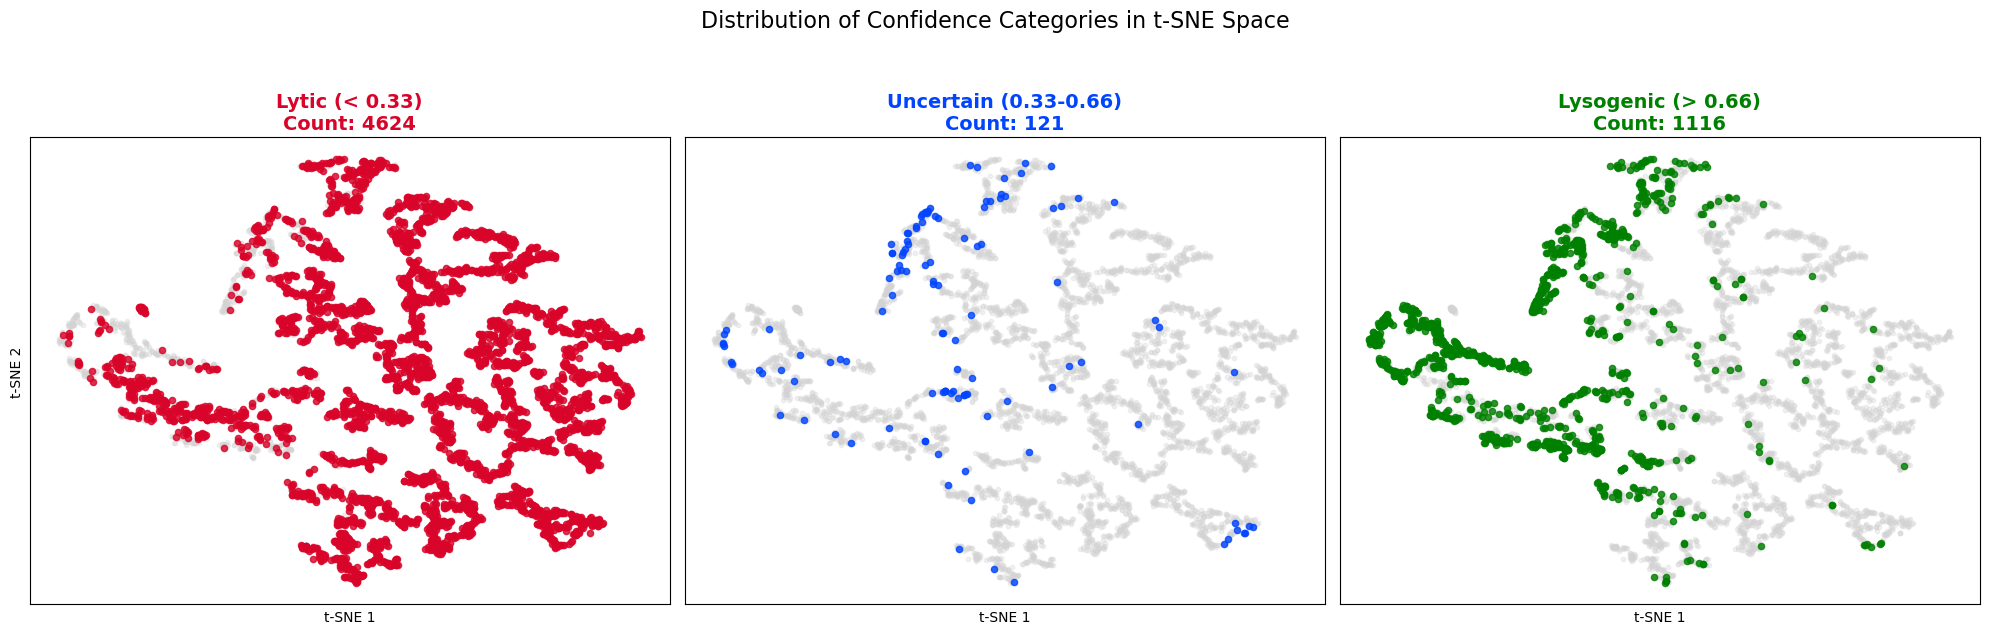

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# We assume 'tsne_results' and 'probs_combined' exist from previous cells.
# If you prefer PCA coordinates, replace 'tsne_results' with 'X_pca' below.
viz_df = pd.DataFrame(tsne_results, columns=['x', 'y'])
viz_df['probability'] = probs_combined

# Assign categories
def get_category(p):
    if p < 0.33: return 'Lytic (< 0.33)'
    elif p <= 0.66: return 'Uncertain (0.33-0.66)'
    else: return 'Lysogenic (> 0.66)'

viz_df['category'] = viz_df['probability'].apply(get_category)

# Define configurations for the 3 plots
categories = [
    {'name': 'Lytic (< 0.33)',        'color': '#D90429', 'subset': viz_df[viz_df['probability'] < 0.33]},
    {'name': 'Uncertain (0.33-0.66)', 'color': '#0044FF', 'subset': viz_df[(viz_df['probability'] >= 0.33) & (viz_df['probability'] <= 0.66)]},
    {'name': 'Lysogenic (> 0.66)',    'color': '#008000', 'subset': viz_df[viz_df['probability'] > 0.66]}
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# Determine global limits so all plots share the same scale
x_min, x_max = viz_df['x'].min(), viz_df['x'].max()
y_min, y_max = viz_df['y'].min(), viz_df['y'].max()
pad_x = (x_max - x_min) * 0.05
pad_y = (y_max - y_min) * 0.05


for ax, cat in zip(axes, categories):
    subset = cat['subset']
    
    # Plot all points as faint grey background for context (optional, makes comparison easier)
    # If you want ONLY the points of the category, comment out the next line.
    ax.scatter(viz_df['x'], viz_df['y'], c='lightgrey', s=10, alpha=0.3, label='Other')
    
    # Plot the specific category points
    ax.scatter(subset['x'], subset['y'], c=cat['color'], s=20, alpha=0.8, label=cat['name'])
    
    # Styling
    ax.set_title(f"{cat['name']}\nCount: {len(subset)}", fontsize=14, fontweight='bold', color=cat['color'])
    ax.set_xlim(x_min - pad_x, x_max + pad_x)
    ax.set_ylim(y_min - pad_y, y_max + pad_y)
    ax.set_xlabel("t-SNE 1")
    if ax == axes[0]:
        ax.set_ylabel("t-SNE 2")
    
    # Remove ticks for cleaner look
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Distribution of Confidence Categories in t-SNE Space", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

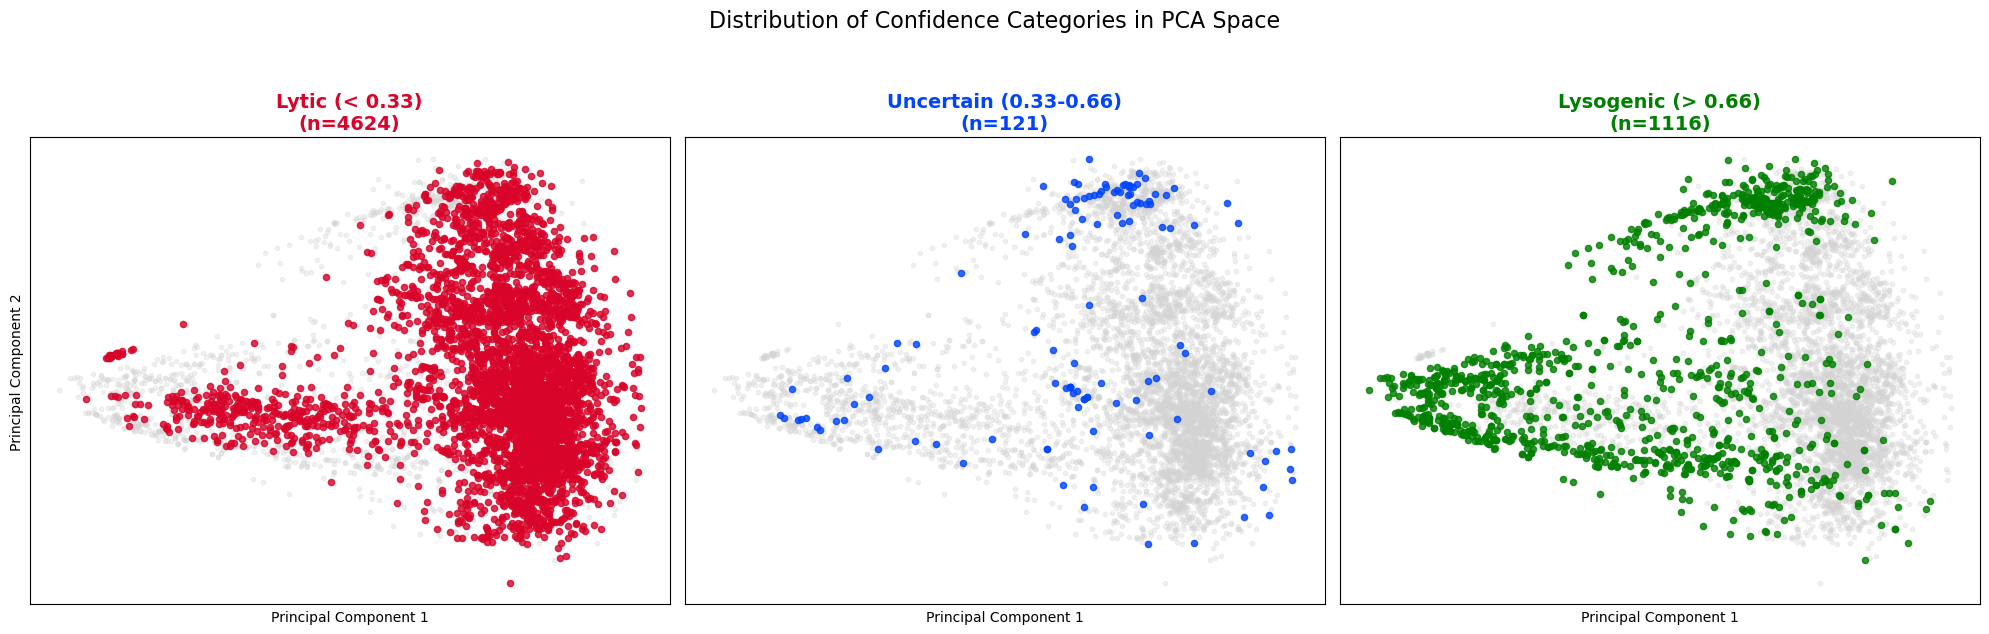

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Prepare Data for PCA
# ---------------------------------------------------------
# We use 'X_pca' (which contains the PCA coordinates) and 'probs_combined'
viz_df_pca = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
viz_df_pca['probability'] = probs_combined

# Assign categories
def get_category(p):
    if p < 0.33: return 'Lytic (< 0.33)'
    elif p <= 0.66: return 'Uncertain (0.33-0.66)'
    else: return 'Lysogenic (> 0.66)'

viz_df_pca['category'] = viz_df_pca['probability'].apply(get_category)

# Define configurations for the 3 categories
categories = [
    {'name': 'Lytic (< 0.33)',        'color': '#D90429', 'subset': viz_df_pca[viz_df_pca['probability'] < 0.33]},
    {'name': 'Uncertain (0.33-0.66)', 'color': '#0044FF', 'subset': viz_df_pca[(viz_df_pca['probability'] >= 0.33) & (viz_df_pca['probability'] <= 0.66)]},
    {'name': 'Lysogenic (> 0.66)',    'color': '#008000', 'subset': viz_df_pca[viz_df_pca['probability'] > 0.66]}
]

# 2. Setup Plotting
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# Determine global limits so all plots share the same scale
x_min, x_max = viz_df_pca['PC1'].min(), viz_df_pca['PC1'].max()
y_min, y_max = viz_df_pca['PC2'].min(), viz_df_pca['PC2'].max()
pad_x = (x_max - x_min) * 0.05
pad_y = (y_max - y_min) * 0.05

# 3. Generate Subplots
# ---------------------------------------------------------
for ax, cat in zip(axes, categories):
    subset = cat['subset']
    
    # Plot ALL points as faint grey background for context
    ax.scatter(viz_df_pca['PC1'], viz_df_pca['PC2'], c='lightgrey', s=10, alpha=0.3, label='Other')
    
    # Plot the SPECIFIC category points on top
    ax.scatter(subset['PC1'], subset['PC2'], c=cat['color'], s=20, alpha=0.8, label=cat['name'])
    
    # Styling
    ax.set_title(f"{cat['name']}\n(n={len(subset)})", fontsize=14, fontweight='bold', color=cat['color'])
    ax.set_xlim(x_min - pad_x, x_max + pad_x)
    ax.set_ylim(y_min - pad_y, y_max + pad_y)
    ax.set_xlabel("Principal Component 1")
    if ax == axes[0]:
        ax.set_ylabel("Principal Component 2")
    
    # Remove ticks for cleaner look
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Distribution of Confidence Categories in PCA Space", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()